# J5 — Classification par embeddings `bge-m3` → Régression Logistique + calibration

**Cible (fixée en séance, alignée sur J3)** — le succès n'est *pas* un macro-F1 synthétique élevé,
mais **réduire l'écart synthétique → réel** :

$$\text{écart} = \text{macroF1}(\text{gold synthétique}) - \text{macroF1}(\text{validation externe réelle})$$

Référence J3 (TF-IDF+SVM) : **0,944 → 0,388, écart = 0,556**. On veut un écart plus faible,
prioritairement en **remontant le réel** grâce au sémantique multilingue de `bge-m3`.

**Règle d'or méthodologique** — le **gold (102)** et la **validation externe (46)** restent du
**test PUR** : jamais touchés pour entraîner, calibrer ou régler le seuil. La calibration et le
seuil d'abstention sont réglés sur un **split *dev* (~15 %) découpé du train**.

Ce notebook **explore** ; le code validé sera figé dans `smart_ticketing_ml/training/train_classifier.py`.
Le harnais `eval/` (métriques, matrices de confusion, étanchéité) est réutilisé tel quel.

In [1]:
%matplotlib inline
import sys, glob, json, time, hashlib
from pathlib import Path
import numpy as np

# Le package est installé (pip -e), mais les chemins de données du harnais sont
# relatifs à la racine `ml/`. On la localise, qu'on lance depuis ml/ ou ml/notebooks/.
CWD = Path.cwd()
ML_ROOT = CWD if (CWD / "smart_ticketing_ml").exists() else CWD.parent
assert (ML_ROOT / "smart_ticketing_ml").exists(), f"racine ml/ introuvable depuis {CWD}"
if str(ML_ROOT) not in sys.path:
    sys.path.insert(0, str(ML_ROOT))  # rend le package importable quel que soit le CWD du kernel

TRAIN = sorted(glob.glob(str(ML_ROOT / "artifacts/corpus/corpus_train_*.jsonl")))[-1]
GOLD = ML_ROOT / "gold/gold.jsonl"
EXTERNE = ML_ROOT / "gold/validation_externe.jsonl"
OUT = ML_ROOT / "artifacts/eval/j5_explore"; OUT.mkdir(parents=True, exist_ok=True)
CACHE = ML_ROOT / "artifacts/eval/j5_cache"; CACHE.mkdir(parents=True, exist_ok=True)
SEED = 42
print("train  :", Path(TRAIN).name)
print("gold   :", GOLD.name, "| externe:", EXTERNE.name)
print("sorties:", OUT)

train  : corpus_train_20260714T161302Z.jsonl
gold   : gold.jsonl | externe: validation_externe.jsonl
sorties: C:\Users\LOQ\Desktop\PFE-Metavoria\ml\artifacts\eval\j5_explore


## 1. Données + rappel d'étanchéité

On charge les trois jeux via le harnais (`eval.dataset`) — même unité d'entrée `titre+description`,
mêmes catégories dynamiques (jamais codées en dur). On re-vérifie l'étanchéité train/test.

In [2]:
from smart_ticketing_ml.eval.dataset import load_train, load_gold, load_exemples, assert_disjoint
from smart_ticketing_ml.eval.report import _ordre_labels

train = load_train(TRAIN)
gold = load_gold(str(GOLD))
externe = load_exemples(str(EXTERNE))
labels = _ordre_labels(train + gold + externe)  # ordre métier, dérivé des données

print(f"train={len(train)}  gold={len(gold)}  externe={len(externe)}")
print("labels:", labels)
for nom, d in [("gold", gold), ("externe", externe)]:
    v = assert_disjoint(train, d)
    print(f"  étanchéité {nom:8}: exactes={len(v.fuites_exactes)}  approx(Jaccard≥{v.seuil_alerte})={len(v.proches)}")

train=852  gold=102  externe=46
labels: ['Logiciel', 'Matériel', 'Réseau', 'Accès', 'Autre']


  étanchéité gold    : exactes=0  approx(Jaccard≥0.6)=8


  étanchéité externe : exactes=0  approx(Jaccard≥0.6)=0


## 2. Embeddings `bge-m3` (source unique = `service.embedder`) + cache `.npy`

On réutilise **exactement** l'embedder du service/backfill (J4) — L2-normalisé, tête dense 1024d.
Les vecteurs sont mis en cache sur disque (clé = nom + n + hash des textes) pour itérer vite sur
les modèles sans ré-encoder (~2 min sinon à chaque exécution).

In [3]:
from smart_ticketing_ml.service.embedder import embed_textes

def _key(exemples):
    h = hashlib.sha1("\x1f".join(e.texte for e in exemples).encode("utf-8")).hexdigest()[:12]
    return f"n{len(exemples)}_{h}"

def embed_cache(name, exemples):
    f = CACHE / f"{name}_{_key(exemples)}.npy"
    if f.exists():
        print(f"{name:8}: cache hit  {f.name}")
        return np.load(f)
    t = time.perf_counter()
    X = np.asarray(embed_textes([e.texte for e in exemples]), dtype=np.float32)
    np.save(f, X)
    print(f"{name:8}: encodé {X.shape} en {time.perf_counter()-t:.1f}s -> {f.name}")
    return X

Xtr = embed_cache("train", train);   ytr = np.array([e.categorie for e in train])
Xg  = embed_cache("gold", gold);     yg  = np.array([e.categorie for e in gold])
Xe  = embed_cache("externe", externe); ye = np.array([e.categorie for e in externe])
print("dims:", Xtr.shape, Xg.shape, Xe.shape)

C:\Users\LOQ\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


C:\Users\LOQ\anaconda3\Lib\site-packages\onnxruntime\capi\onnxruntime_validation.py:26: UserWarning: Unsupported Windows version (11). ONNX Runtime supports Windows 10 and above, only.
  warnings.warn(


train   : encodé (852, 1024) en 145.9s -> train_n852_524722d32969.npy


gold    : encodé (102, 1024) en 7.5s -> gold_n102_0cf226120682.npy


externe : encodé (46, 1024) en 48.5s -> externe_n46_262f7227f0ae.npy
dims: (852, 1024) (102, 1024) (46, 1024)


## 3. Split *dev* stratifié depuis le train (règle d'or)

`train'` sert à **entraîner** la LogReg ; `dev` sert **uniquement** à **calibrer** (Platt/isotonique)
et à **régler le seuil d'abstention**. Le gold et l'externe ne sont jamais vus ici.

In [4]:
from sklearn.model_selection import train_test_split
from collections import Counter

Xtr_fit, Xdev, ytr_fit, ydev = train_test_split(
    Xtr, ytr, test_size=0.15, stratify=ytr, random_state=SEED)
print(f"train'={len(ytr_fit)}  dev={len(ydev)}")
print("répartition dev:", dict(Counter(ydev)))

train'=724  dev=128
répartition dev: {'Logiciel': 38, 'Accès': 19, 'Réseau': 26, 'Autre': 13, 'Matériel': 32}


## 4. Modèles

- **LogReg (embeddings)** — *le choix* (§5). Entraîné sur `train'`.
- **LogReg + Platt (sigmoïde)** et **LogReg + isotonique** — calibrées sur `dev` (`cv="prefit"`).
- **SVM-embeddings (contrôle)** — pour isoler *« embeddings vs TF-IDF »* de *« LogReg vs SVM »*.
- **Baselines J3 en référence** — Majoritaire et TF-IDF+SVM (sur texte brut, comme en J3).

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.svm import LinearSVC
from smart_ticketing_ml.eval import baselines as bl

# --- modèles sur embeddings ---
base_lr = LogisticRegression(max_iter=2000, C=1.0, random_state=SEED).fit(Xtr_fit, ytr_fit)
cal_sig = CalibratedClassifierCV(base_lr, method="sigmoid",  cv="prefit").fit(Xdev, ydev)
cal_iso = CalibratedClassifierCV(base_lr, method="isotonic", cv="prefit").fit(Xdev, ydev)
svm_emb = LinearSVC(random_state=SEED).fit(Xtr_fit, ytr_fit)

# --- baselines J3 de référence (texte brut, entraînées sur tout le train comme en J3) ---
Xtr_text = [e.texte for e in train]
maj      = bl.Majoritaire().fit(Xtr_text, list(ytr))
svm_tfidf = bl.TfidfSvm().fit(Xtr_text, list(ytr))
print("modèles entraînés.")

modèles entraînés.


C:\Users\LOQ\anaconda3\Lib\site-packages\sklearn\svm\_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(


## 5. Tableau d'écart synthétique → réel (macro-F1, la métrique de tête)

On évalue chaque modèle sur **les deux jeux** via `eval.metrics.evaluer`. Colonne clé : **écart**.

In [6]:
from smart_ticketing_ml.eval.metrics import evaluer

gold_text = [e.texte for e in gold]
ext_text  = [e.texte for e in externe]

rows = []
detail = {}
def add(nom, pg, pe):
    rg = evaluer(list(yg), list(pg), labels)
    re_ = evaluer(list(ye), list(pe), labels)
    rows.append({"modele": nom, "f1_synth": rg.macro_f1, "f1_reel": re_.macro_f1,
                 "ecart": rg.macro_f1 - re_.macro_f1,
                 "acc_synth": rg.accuracy, "acc_reel": re_.accuracy})
    detail[nom] = (rg, re_)

add("Majoritaire (plancher)",     maj.predict(gold_text),      maj.predict(ext_text))
add("TF-IDF+SVM (J3, réf.)",      svm_tfidf.predict(gold_text), svm_tfidf.predict(ext_text))
add("SVM-embeddings (contrôle)",  svm_emb.predict(Xg),         svm_emb.predict(Xe))
add("LogReg (embeddings)",        base_lr.predict(Xg),         base_lr.predict(Xe))
add("LogReg + Platt",             cal_sig.predict(Xg),         cal_sig.predict(Xe))
add("LogReg + isotonique",        cal_iso.predict(Xg),         cal_iso.predict(Xe))

# rendu tableau
hdr = f"{'Modèle':<28} {'F1 synth':>9} {'F1 réel':>9} {'écart':>8} {'acc réel':>9}"
print(hdr); print("-" * len(hdr))
for r in rows:
    print(f"{r['modele']:<28} {r['f1_synth']:>9.3f} {r['f1_reel']:>9.3f} "
          f"{r['ecart']:>8.3f} {r['acc_reel']:>9.3f}")

# résumé versionnable (pour lecture hors notebook)
md_lines = ["# J5 — écart synthétique→réel (exploration)\n",
            "| Modèle | F1 synth | F1 réel | écart | acc réel |",
            "|---|---|---|---|---|"]
for r in rows:
    md_lines.append(f"| {r['modele']} | {r['f1_synth']:.3f} | {r['f1_reel']:.3f} "
                    f"| {r['ecart']:.3f} | {r['acc_reel']:.3f} |")
(OUT / "gap_table.md").write_text("\n".join(md_lines) + "\n", encoding="utf-8")
(OUT / "gap_table.json").write_text(json.dumps(rows, ensure_ascii=False, indent=2), encoding="utf-8")
print("\n-> écrit", OUT / "gap_table.md")

Modèle                        F1 synth   F1 réel    écart  acc réel
-------------------------------------------------------------------
Majoritaire (plancher)           0.096     0.125   -0.030     0.457
TF-IDF+SVM (J3, réf.)            0.944     0.388    0.556     0.391
SVM-embeddings (contrôle)        0.944     0.428    0.515     0.478
LogReg (embeddings)              0.944     0.438    0.506     0.500
LogReg + Platt                   0.944     0.442    0.501     0.500
LogReg + isotonique              0.897     0.340    0.557     0.348

-> écrit C:\Users\LOQ\Desktop\PFE-Metavoria\ml\artifacts\eval\j5_explore\gap_table.md


In [7]:
# Barres d'écart (plus court = meilleur transfert synthétique->réel)
import matplotlib.pyplot as plt
noms = [r["modele"] for r in rows]
fs = [r["f1_synth"] for r in rows]; fr = [r["f1_reel"] for r in rows]
y = np.arange(len(noms)); h = 0.38
fig, ax = plt.subplots(figsize=(9, 0.7*len(noms)+1))
ax.barh(y+h/2, fs, h, label="Gold synthétique", color="#94a3b8")
ax.barh(y-h/2, fr, h, label="Validation externe réelle", color="#2563eb")
ax.set_yticks(y, noms); ax.invert_yaxis(); ax.set_xlim(0, 1)
ax.set_xlabel("macro-F1"); ax.set_title("macro-F1 : synthétique vs réel (J5)")
ax.legend(loc="lower right"); ax.grid(axis="x", alpha=0.3)
fig.tight_layout(); fig.savefig(OUT / "gap_bars.png", dpi=120); plt.show()

C:\Users\LOQ\AppData\Local\Temp\ipykernel_2212\3546234156.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); fig.savefig(OUT / "gap_bars.png", dpi=120); plt.show()


## 6. Matrices de confusion — LogReg (embeddings), sur les deux jeux

On réutilise `report._plot_confusion` du harnais.

Par classe — LogReg sur validation externe réelle :
classe          P      R     F1    n
Logiciel    0.889  0.381  0.533   21
Matériel    0.545  0.750  0.632    8
Réseau      0.583  0.700  0.636   10
Accès       0.250  0.200  0.222    5
Autre       0.100  0.500  0.167    2


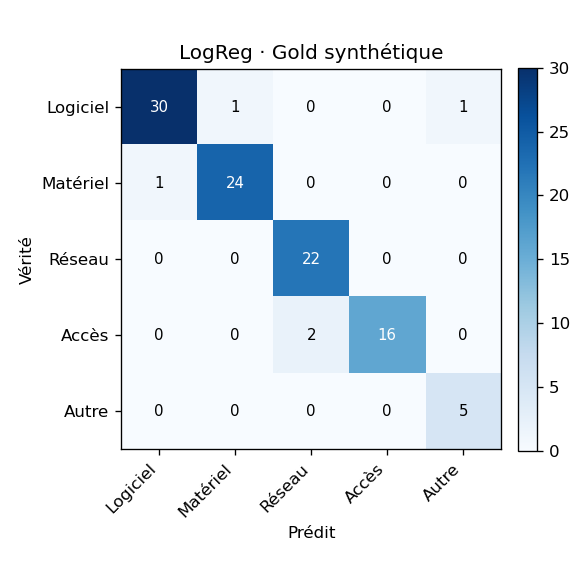

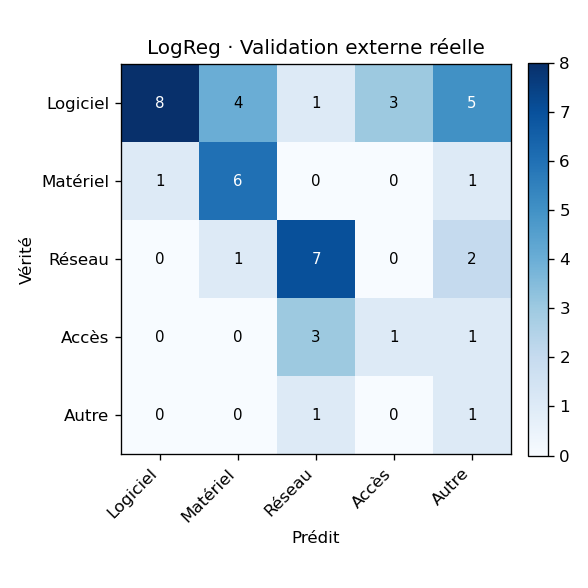

In [8]:
from smart_ticketing_ml.eval.report import _plot_confusion
rg_lr, re_lr = detail["LogReg (embeddings)"]
_plot_confusion(rg_lr, OUT / "cm_logreg_gold.png",    "LogReg · Gold synthétique")
_plot_confusion(re_lr, OUT / "cm_logreg_externe.png", "LogReg · Validation externe réelle")

# détail par classe sur le réel (le test qui compte)
print("Par classe — LogReg sur validation externe réelle :")
print(f"{'classe':<10} {'P':>6} {'R':>6} {'F1':>6} {'n':>4}")
for lab in re_lr.labels:
    c = re_lr.par_classe[lab]
    print(f"{lab:<10} {c['precision']:>6.3f} {c['recall']:>6.3f} {c['f1']:>6.3f} {c['support']:>4}")

from IPython.display import Image, display
for p in ["cm_logreg_gold.png", "cm_logreg_externe.png"]:
    display(Image(str(OUT / p)))

## 7. Calibration — reliability diagram + ECE

Une confiance *calibrée* : « 0,8 » doit vouloir dire « juste ~80 % du temps ». On compare
**non calibré vs Platt vs isotonique** via l'**ECE** (Expected Calibration Error) sur la confiance
top-1, et le **reliability diagram**. L'écart argmax entre calibré/non-calibré est faible : la
calibration change la *confiance*, pas (ou peu) la *décision* — c'est le but.

In [9]:
def ece_reliability(model, X, y_true, n_bins=10):
    proba = model.predict_proba(X)
    classes = model.classes_
    conf = proba.max(axis=1)
    pred = classes[proba.argmax(axis=1)]
    correct = (pred == np.asarray(y_true)).astype(float)
    edges = np.linspace(0, 1, n_bins + 1)
    ece, xs, ys, ns = 0.0, [], [], []
    for i in range(n_bins):
        lo, hi = edges[i], edges[i + 1]
        m = (conf > lo) & (conf <= hi) if i > 0 else (conf >= lo) & (conf <= hi)
        if not m.any():
            continue
        acc, cbar, w = correct[m].mean(), conf[m].mean(), m.mean()
        ece += w * abs(acc - cbar)
        xs.append(cbar); ys.append(acc); ns.append(int(m.sum()))
    return ece, xs, ys, ns

variantes = {"Non calibré": base_lr, "Platt": cal_sig, "Isotonique": cal_iso}

# Table ECE sur les deux jeux
print(f"{'variante':<14} {'ECE synth':>10} {'ECE réel':>10}")
ece_rows = []
for nom, mdl in variantes.items():
    e_s, *_ = ece_reliability(mdl, Xg, yg)
    e_r, *_ = ece_reliability(mdl, Xe, ye)
    ece_rows.append({"variante": nom, "ece_synth": round(e_s, 4), "ece_reel": round(e_r, 4)})
    print(f"{nom:<14} {e_s:>10.4f} {e_r:>10.4f}")
(OUT / "ece_table.json").write_text(json.dumps(ece_rows, ensure_ascii=False, indent=2), encoding="utf-8")

variante        ECE synth   ECE réel
Non calibré        0.2570     0.0540
Platt              0.0689     0.2821
Isotonique         0.0572     0.4946


257

In [10]:
# Reliability diagram sur la validation externe RÉELLE (le test honnête)
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "--", color="gray", label="parfait")
for nom, mdl in variantes.items():
    e_r, xs, ys, ns = ece_reliability(mdl, Xe, ye)
    ax.plot(xs, ys, "o-", label=f"{nom} (ECE={e_r:.3f})")
ax.set_xlabel("confiance moyenne (top-1)"); ax.set_ylabel("accuracy empirique")
ax.set_title("Reliability diagram — validation externe réelle")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(loc="upper left"); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(OUT / "reliability_externe.png", dpi=120); plt.show()

C:\Users\LOQ\AppData\Local\Temp\ipykernel_2212\1961374072.py:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); fig.savefig(OUT / "reliability_externe.png", dpi=120); plt.show()


## 8. Abstention — seuil réglé sur *dev*, appliqué au test

Politique produit (§8) : sous le seuil de confiance → **abstention** plutôt que prédiction forcée.
Le seuil est choisi **sur le dev** pour viser une précision ~0,8 sur le couvert, puis appliqué tel
quel au gold et à l'externe. On rapporte **couverture** vs **précision sur le couvert** — le vrai
point de fonctionnement, distinct du macro-F1 argmax (comparable aux baselines) montré plus haut.

In [11]:
CAL = cal_sig  # variante calibrée retenue pour l'exploration (Platt)

def couverture_precision(model, X, y, seuil):
    proba = model.predict_proba(X); classes = model.classes_
    conf = proba.max(1); pred = classes[proba.argmax(1)]
    couvert = conf >= seuil
    if couvert.sum() == 0:
        return 0.0, float("nan")
    prec = (pred[couvert] == np.asarray(y)[couvert]).mean()
    return couvert.mean(), prec

# seuil qui atteint précision>=0.80 sur le dev (couverture maximale à cette contrainte)
cible = 0.80
grille = np.linspace(0.30, 0.95, 66)
choisi = None
for s in grille:
    cov, prec = couverture_precision(CAL, Xdev, ydev, s)
    if cov > 0 and prec >= cible:
        choisi = s; break
choisi = choisi if choisi is not None else 0.5
cov_dev, prec_dev = couverture_precision(CAL, Xdev, ydev, choisi)
print(f"seuil choisi sur dev = {choisi:.3f}  (dev: couverture={cov_dev:.2%}, précision={prec_dev:.2%})")

print(f"\n{'jeu':<18} {'couverture':>11} {'précision couvert':>18}")
for nom, X, y in [("gold synth", Xg, yg), ("externe réel", Xe, ye)]:
    cov, prec = couverture_precision(CAL, X, y, choisi)
    print(f"{nom:<18} {cov:>11.2%} {prec:>18.2%}")

seuil choisi sur dev = 0.300  (dev: couverture=100.00%, précision=97.66%)

jeu                 couverture  précision couvert
gold synth             100.00%             95.10%
externe réel           100.00%             50.00%


In [12]:
# Courbe couverture-précision sur l'externe (compromis d'abstention)
covs, precs = [], []
for s in grille:
    cov, prec = couverture_precision(CAL, Xe, ye, s)
    covs.append(cov); precs.append(prec)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(covs, precs, "o-", color="#2563eb")
ax.axhline(cible, ls="--", color="gray", label=f"cible précision {cible:.0%}")
cov_star, prec_star = couverture_precision(CAL, Xe, ye, choisi)
ax.scatter([cov_star], [prec_star], color="red", zorder=5,
           label=f"seuil dev={choisi:.2f}")
ax.set_xlabel("couverture"); ax.set_ylabel("précision sur le couvert")
ax.set_title("Abstention — compromis couverture/précision (externe réel)")
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(OUT / "abstention_externe.png", dpi=120); plt.show()

C:\Users\LOQ\AppData\Local\Temp\ipykernel_2212\1465280017.py:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); fig.savefig(OUT / "abstention_externe.png", dpi=120); plt.show()


## 9. Conclusion d'exploration

À lire dans le tableau §5 (écart) et le reliability §7 :

- **Le sémantique réduit-il l'écart** vs TF-IDF+SVM (0,556) ? → colonne `écart` de `LogReg (embeddings)`.
- **Calibration** : Platt vs isotonique — laquelle baisse l'ECE réel sans casser le macro-F1 ?
- **Modèle à figer** dans `training/train_classifier.py` = LogReg (embeddings) + variante de
  calibration retenue + seuil d'abstention réglé sur dev.

> Décision de gel à valider avec Fedi **avant** d'écrire le script et d'étendre le harnais
> (ECE + reliability dans `eval/`), le rapport de référence `ml/eval/reports/j5/`, et le journal.